In [1]:
import sys, os
sys.path.append(os.path.abspath('..'))

import numpy as np
import pandas as pd
import geopandas as gpd
import copy
import torch
from torch.utils.data import DataLoader, Subset, Dataset
from imblearn.over_sampling import SMOTE

from src.data.labeling import generate_sample_grid, assign_risk_labels, prepare_fire_dates
from src.data.real_data import AlaskaWildfireRealDataset, spatial_block_split_real
from src.models.cnn_lstm import build_model, FocalLoss
from src.training.train import load_config, run_epoch, class_weights_from_labels
from src.evaluation.metrics import get_predictions, compute_metrics, plot_confusion_matrix
import matplotlib.pyplot as plt

cfg = load_config('../config/config.yaml')
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [2]:
perimeters = gpd.read_file(
    '../data/raw/AlaskaFireHistory_PerimeterPolygons_AKAlbersNAD83_geojson/AlaskaFireHistory_Polygons_AKAlbersNAD83_geojson.geojson'
)
perimeters = perimeters.to_crs(epsg=4326)
print(len(perimeters), 'fire perimeters loaded')

5943 fire perimeters loaded


In [3]:
sample_dates = ['2018-06-01', '2019-06-01', '2020-06-01', '2021-06-01', '2022-06-01', '2023-06-01']
points = generate_sample_grid(
    bounds=(-148.9, 63.5, -145.3, 65.5),
    sample_dates=sample_dates,
    spacing_deg=0.1,
)
print(len(points), 'points')


4320 points


In [4]:
labeled_points = assign_risk_labels(perimeters, points, horizon_months=1, buffer_km=30, high_buffer_km=10.0)
labeled_points.to_file('../data/processed/labeled_points.geojson', driver='GeoJSON')
print(labeled_points['risk_label'].value_counts())

risk_label
NO_RISK     3108
MODERATE    1034
HIGH         178
Name: count, dtype: int64


In [5]:
real_dataset = AlaskaWildfireRealDataset(
    processed_dir='../data/processed',
    labeled_points_path='../data/processed/labeled_points.geojson'
)
print(len(real_dataset), 'real samples loaded')
print('spatial channels:', real_dataset.n_spatial_channels)
print('weather features:', real_dataset.n_weather_features)

1586 real samples loaded
spatial channels: 7
weather features: 3


In [6]:
cfg['data']['n_weather_features'] = real_dataset.n_weather_features
cfg['model']['num_classes'] = 3

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = build_model(cfg, real_dataset.n_spatial_channels, real_dataset.n_weather_features).to(device)

In [7]:
SPLIT_SEED = 42  # change this if any split below shows a missing class

train_idx, val_idx, test_idx = spatial_block_split_real(real_dataset, seed=SPLIT_SEED)

for name, idxs in [('train', train_idx), ('val', val_idx), ('test', test_idx)]:
    labels = [real_dataset[i]['label'].item() for i in idxs]
    print(name, len(idxs), np.bincount(labels, minlength=3))

batch_size = min(cfg['training']['batch_size'], max(2, len(train_idx) // 4))
train_loader = DataLoader(Subset(real_dataset, train_idx), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(Subset(real_dataset, val_idx), batch_size=batch_size, shuffle=False)
test_loader = DataLoader(Subset(real_dataset, test_idx), batch_size=batch_size, shuffle=False)

train 1138 [808 282  48]
val 218 [186  29   3]
test 230 [204  23   3]


In [8]:
def flatten_sample(dataset, idx):
    sample = dataset[idx]
    spatial_flat = sample['spatial'].numpy().flatten()
    weather_flat = sample['weather'].numpy().flatten()
    return np.concatenate([spatial_flat, weather_flat])

X_train = np.stack([flatten_sample(real_dataset, i) for i in train_idx])
y_train = np.array([real_dataset[i]['label'].item() for i in train_idx])

SPATIAL_SHAPE = real_dataset[0]['spatial'].shape
WEATHER_SHAPE = real_dataset[0]['weather'].shape
print('X_train shape:', X_train.shape)
print('spatial shape:', SPATIAL_SHAPE, 'weather shape:', WEATHER_SHAPE)

X_train shape: (1138, 7258)
spatial shape: torch.Size([7, 32, 32]) weather shape: torch.Size([30, 3])


In [9]:
class_names = cfg['data']['classes']

class SmoteAugmentedDataset(torch.utils.data.Dataset):
    def __init__(self, spatial_arr, weather_arr, labels_arr):
        self.spatial = spatial_arr.astype(np.float32)
        self.weather = weather_arr.astype(np.float32)
        self.labels = labels_arr.astype(np.int64)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return {
            'spatial': torch.from_numpy(self.spatial[i]),
            'weather': torch.from_numpy(self.weather[i]),
            'label': torch.tensor(self.labels[i], dtype=torch.long),
        }


def run_smote_experiment(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)

    smote = SMOTE(k_neighbors=5, random_state=seed)
    X_train_s, y_train_s = smote.fit_resample(X_train, y_train)

    spatial_size = int(np.prod(SPATIAL_SHAPE))
    X_sp = X_train_s[:, :spatial_size].reshape(-1, *SPATIAL_SHAPE)
    X_we = X_train_s[:, spatial_size:].reshape(-1, *WEATHER_SHAPE)

    train_ds = SmoteAugmentedDataset(X_sp, X_we, y_train_s)
    train_loader_s = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

    model_s = build_model(cfg, real_dataset.n_spatial_channels, real_dataset.n_weather_features).to(device)
    criterion_s = FocalLoss(gamma=cfg['training']['focal_gamma'])
    optimizer_s = torch.optim.Adam(model_s.parameters(), lr=cfg['training']['learning_rate'])

    best_val_loss = float('inf')
    best_state = None
    for epoch in range(cfg['training']['epochs']):
        run_epoch(model_s, train_loader_s, criterion_s, optimizer_s, device, train=True)
        val_loss, _ = run_epoch(model_s, val_loader, criterion_s, optimizer_s, device, train=False)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model_s.state_dict())

    model_s.load_state_dict(best_state)
    y_pred_s, y_probs_s, y_true_s = get_predictions(model_s, test_loader, device=device)
    m = compute_metrics(y_true_s, y_pred_s, y_probs_s, class_names)
    return m['accuracy'], m['macro_f1'], model_s

In [10]:
results = []
best_model = None
best_acc = -1

for seed in [1, 2, 3, 4, 5]:
    acc, f1, model_s = run_smote_experiment(seed)
    print(f'seed={seed}: accuracy={acc:.3f}  macro_f1={f1:.3f}')
    results.append((acc, f1))
    if acc > best_acc:
        best_acc = acc
        best_model = model_s

accs = [r[0] for r in results]
f1s = [r[1] for r in results]
print()
print(f'Mean accuracy: {np.mean(accs):.3f} ± {np.std(accs):.3f}')
print(f'Mean macro F1: {np.mean(f1s):.3f} ± {np.std(f1s):.3f}')
print(f'Range: {min(accs):.3f} to {max(accs):.3f}')

os.makedirs('../outputs/checkpoints', exist_ok=True)
torch.save(best_model.state_dict(), '../outputs/checkpoints/cnn_lstm_real_fairbanks.pt')
print('Saved best-performing model for dashboard use.')

seed=1: accuracy=0.739  macro_f1=0.340
seed=2: accuracy=0.865  macro_f1=0.522
seed=3: accuracy=0.826  macro_f1=0.428
seed=4: accuracy=0.865  macro_f1=0.496
seed=5: accuracy=0.796  macro_f1=0.443

Mean accuracy: 0.818 ± 0.047
Mean macro F1: 0.446 ± 0.063
Range: 0.739 to 0.865
Saved best-performing model for dashboard use.


              precision    recall  f1-score   support

     NO_RISK       0.93      0.94      0.94       204
    MODERATE       0.33      0.17      0.23        23
        HIGH       0.25      1.00      0.40         3

    accuracy                           0.87       230
   macro avg       0.51      0.71      0.52       230
weighted avg       0.86      0.87      0.86       230



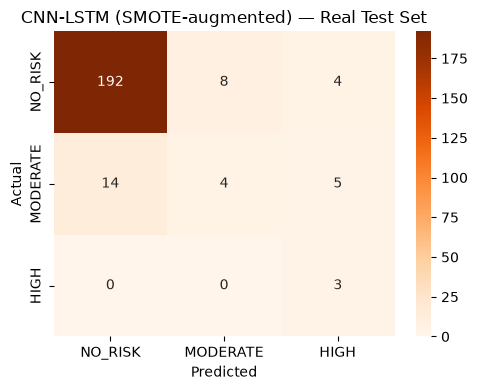

In [11]:
y_pred, y_probs, y_true = get_predictions(best_model, test_loader, device=device)
metrics = compute_metrics(y_true, y_pred, y_probs, class_names)
print(metrics['report'])

os.makedirs('../outputs/figures', exist_ok=True)
fig = plot_confusion_matrix(y_true, y_pred, class_names,
                             save_path='../outputs/figures/confusion_matrix_smote.png',
                             title='CNN-LSTM (SMOTE-augmented) — Real Test Set')
plt.show()

In [12]:
from src.training.train import train_baselines

baseline_results = train_baselines(real_dataset, train_loader, test_loader, cfg)
print(f"{'CNN-LSTM (mean of 5 runs)':30s}{np.mean(accs):>15.3f}")
for name, res in baseline_results.items():
    print(f"{name:30s}{res['test_acc']:>15.3f}")

LogisticRegression: test accuracy = 0.939
RandomForest: test accuracy = 0.922
XGBoost: test accuracy = 0.939
CNN-LSTM (mean of 5 runs)               0.818
LogisticRegression                      0.939
RandomForest                            0.922
XGBoost                                 0.939


In [13]:
3 # Regenerate labels for the SAME points/patches, just with different horizons.
# No new GEE extraction needed — the satellite/weather data doesn't change,
# only whether a fire happened within 3 or 6 months counts as HIGH/MODERATE.

labeled_points_h3 = assign_risk_labels(perimeters, points, horizon_months=3, buffer_km=30, high_buffer_km=10.0)
labeled_points_h3.to_file('../data/processed/labeled_points_h3.geojson', driver='GeoJSON')
print('3-month horizon:')
print(labeled_points_h3['risk_label'].value_counts())

print()

labeled_points_h6 = assign_risk_labels(perimeters, points, horizon_months=6, buffer_km=30, high_buffer_km=10.0)
labeled_points_h6.to_file('../data/processed/labeled_points_h6.geojson', driver='GeoJSON')
print('6-month horizon:')
print(labeled_points_h6['risk_label'].value_counts())

3-month horizon:
risk_label
NO_RISK     2051
MODERATE    1693
HIGH         576
Name: count, dtype: int64

6-month horizon:
risk_label
NO_RISK     1908
MODERATE    1673
HIGH         739
Name: count, dtype: int64


In [14]:
def train_and_evaluate_horizon(labeled_points_path, horizon_label, seeds=[1, 2, 3, 4, 5]):
    from importlib import reload
    import src.data.real_data
    reload(src.data.real_data)
    from src.data.real_data import AlaskaWildfireRealDataset, spatial_block_split_real

    dataset = AlaskaWildfireRealDataset(
        processed_dir='../data/processed',
        labeled_points_path=labeled_points_path
    )
    print(f'{horizon_label}: {len(dataset)} samples')
    print(dataset.gdf.loc[dataset.indices, 'risk_label'].value_counts())

    train_idx, val_idx, test_idx = spatial_block_split_real(dataset)
    batch_sz = min(cfg['training']['batch_size'], max(2, len(train_idx) // 4))
    val_loader_h = DataLoader(Subset(dataset, val_idx), batch_size=batch_sz, shuffle=False)
    test_loader_h = DataLoader(Subset(dataset, test_idx), batch_size=batch_sz, shuffle=False)

    def flatten_sample(ds, idx):
        s = ds[idx]
        return np.concatenate([s['spatial'].numpy().flatten(), s['weather'].numpy().flatten()])

    X_tr = np.stack([flatten_sample(dataset, i) for i in train_idx])
    y_tr = np.array([dataset[i]['label'].item() for i in train_idx])

    spatial_size = int(np.prod(SPATIAL_SHAPE))  # add this line

    results = []
    best_model = None
    best_acc = -1
    for seed in seeds:
        torch.manual_seed(seed)
        np.random.seed(seed)

        sm = SMOTE(k_neighbors=5, random_state=seed)
        X_s, y_s = sm.fit_resample(X_tr, y_tr)
        X_sp = X_s[:, :spatial_size].reshape(-1, *SPATIAL_SHAPE)
        X_we = X_s[:, spatial_size:].reshape(-1, *WEATHER_SHAPE)
        train_ds = SmoteAugmentedDataset(X_sp, X_we, y_s)
        train_loader_h = DataLoader(train_ds, batch_size=batch_sz, shuffle=True)

        model_h = build_model(cfg, dataset.n_spatial_channels, dataset.n_weather_features).to(device)
        criterion_h = FocalLoss(gamma=cfg['training']['focal_gamma'])
        optimizer_h = torch.optim.Adam(model_h.parameters(), lr=cfg['training']['learning_rate'])

        best_val_loss = float('inf')
        best_state = None
        for epoch in range(cfg['training']['epochs']):
            run_epoch(model_h, train_loader_h, criterion_h, optimizer_h, device, train=True)
            vloss, _ = run_epoch(model_h, val_loader_h, criterion_h, optimizer_h, device, train=False)
            if vloss < best_val_loss:
                best_val_loss = vloss
                best_state = copy.deepcopy(model_h.state_dict())

        model_h.load_state_dict(best_state)
        yp, ypr, yt = get_predictions(model_h, test_loader_h, device=device)
        m = compute_metrics(yt, yp, ypr, class_names)
        print(f'  seed={seed}: accuracy={m["accuracy"]:.3f} macro_f1={m["macro_f1"]:.3f}')
        results.append((m['accuracy'], m['macro_f1']))

        if m['accuracy'] > best_acc:
            best_acc = m['accuracy']
            best_model = model_h

    accs = [r[0] for r in results]
    f1s = [r[1] for r in results]
    print(f'  Mean accuracy: {np.mean(accs):.3f} ± {np.std(accs):.3f}')
    print(f'  Mean macro F1: {np.mean(f1s):.3f} ± {np.std(f1s):.3f}')

    return best_model, np.mean(accs), np.std(accs)


print('=== 3-month horizon ===')
model_h3, acc_h3, std_h3 = train_and_evaluate_horizon('../data/processed/labeled_points_h3.geojson', '3-month')
torch.save(model_h3.state_dict(), '../outputs/checkpoints/cnn_lstm_real_fairbanks_h3.pt')

print()
print('=== 6-month horizon ===')
model_h6, acc_h6, std_h6 = train_and_evaluate_horizon('../data/processed/labeled_points_h6.geojson', '6-month')
torch.save(model_h6.state_dict(), '../outputs/checkpoints/cnn_lstm_real_fairbanks_h6.pt')

=== 3-month horizon ===
3-month: 1586 samples
risk_label
NO_RISK     938
MODERATE    514
HIGH        134
Name: count, dtype: int64
  seed=1: accuracy=0.770 macro_f1=0.591
  seed=2: accuracy=0.722 macro_f1=0.547
  seed=3: accuracy=0.739 macro_f1=0.562
  seed=4: accuracy=0.748 macro_f1=0.531
  seed=5: accuracy=0.752 macro_f1=0.556
  Mean accuracy: 0.746 ± 0.016
  Mean macro F1: 0.557 ± 0.020

=== 6-month horizon ===
6-month: 1586 samples
risk_label
NO_RISK     937
MODERATE    515
HIGH        134
Name: count, dtype: int64
  seed=1: accuracy=0.748 macro_f1=0.610
  seed=2: accuracy=0.752 macro_f1=0.555
  seed=3: accuracy=0.761 macro_f1=0.588
  seed=4: accuracy=0.735 macro_f1=0.518
  seed=5: accuracy=0.717 macro_f1=0.571
  Mean accuracy: 0.743 ± 0.015
  Mean macro F1: 0.568 ± 0.031


In [15]:
import os
print(os.path.exists('../outputs/checkpoints/cnn_lstm_real_fairbanks_h3.pt'))
print(os.path.exists('../outputs/checkpoints/cnn_lstm_real_fairbanks_h6.pt'))

True
True


In [16]:
import shutil
shutil.copy('../outputs/checkpoints/cnn_lstm_real_fairbanks.pt', '../outputs/checkpoints/cnn_lstm_real_fairbanks_h1.pt')

'../outputs/checkpoints/cnn_lstm_real_fairbanks_h1.pt'

In [17]:
import os
for h in ['h1', 'h3', 'h6']:
    path = f'../outputs/checkpoints/cnn_lstm_real_fairbanks_{h}.pt'
    print(h, os.path.exists(path))

h1 True
h3 True
h6 True


In [19]:
import numpy as np, geopandas as gpd
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, precision_recall_fscore_support
from xgboost import XGBClassifier

ids = real_dataset.indices
years = labeled_points.loc[ids, 'sample_date'].dt.year.values
print(np.unique(years, return_counts=True))          # which years survived?

X = np.stack([np.concatenate([real_dataset[i]['spatial'].numpy().ravel(),
                              real_dataset[i]['weather'].numpy().ravel()])
              for i in range(len(real_dataset))])
tiles = real_dataset.tile_ids
LM = {'NO_RISK': 0, 'MODERATE': 1, 'HIGH': 2}
paths = {1: '../data/processed/labeled_points.geojson',
         3: '../data/processed/labeled_points_h3.geojson',
         6: '../data/processed/labeled_points_h6.geojson'}
models = {
    'Majority': lambda: DummyClassifier(strategy='most_frequent'),
    'LogReg':   lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')),
    'RF':       lambda: RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=0),
    'XGB':      lambda: XGBClassifier(n_estimators=200, max_depth=5, eval_metric='mlogloss', random_state=0),
}
splitters = {'tile 5-fold': (GroupKFold(5), tiles), 'leave-one-year-out': (LeaveOneGroupOut(), years)}

for h, p in paths.items():
    y = gpd.read_file(p).loc[ids, 'risk_label'].map(LM).values
    print(f'\n=== {h}-month: class counts {np.bincount(y, minlength=3)} ===')
    for sname, (sp, grp) in splitters.items():
        for mname, make in models.items():
            pred = np.empty_like(y)
            for tr, te in sp.split(X, y, grp):
                clf = make().fit(X[tr], y[tr]); pred[te] = clf.predict(X[te])
            pr, rc, _, _ = precision_recall_fscore_support(y, pred, labels=[2], zero_division=0)
            print(f'{sname:18s}{mname:9s} acc={np.mean(pred==y):.3f} '
                  f'macroF1={f1_score(y, pred, average="macro"):.3f} HIGH P={pr[0]:.2f} R={rc[0]:.2f}')

(array([2018, 2019, 2020], dtype=int32), array([421, 471, 694]))

=== 1-month: class counts [1198  334   54] ===
tile 5-fold       Majority  acc=0.755 macroF1=0.287 HIGH P=0.00 R=0.00
tile 5-fold       LogReg    acc=0.781 macroF1=0.535 HIGH P=0.15 R=0.33
tile 5-fold       RF        acc=0.796 macroF1=0.547 HIGH P=0.47 R=0.17
tile 5-fold       XGB       acc=0.818 macroF1=0.538 HIGH P=0.62 R=0.09
leave-one-year-outMajority  acc=0.755 macroF1=0.287 HIGH P=0.00 R=0.00
leave-one-year-outLogReg    acc=0.578 macroF1=0.353 HIGH P=0.00 R=0.00
leave-one-year-outRF        acc=0.755 macroF1=0.287 HIGH P=0.00 R=0.00
leave-one-year-outXGB       acc=0.765 macroF1=0.330 HIGH P=0.00 R=0.00

=== 3-month: class counts [938 514 134] ===
tile 5-fold       Majority  acc=0.591 macroF1=0.248 HIGH P=0.00 R=0.00
tile 5-fold       LogReg    acc=0.716 macroF1=0.591 HIGH P=0.26 R=0.52
tile 5-fold       RF        acc=0.743 macroF1=0.622 HIGH P=0.40 R=0.45
tile 5-fold       XGB       acc=0.769 macroF1=0.604 HIGH P=0.

In [20]:
y = gpd.read_file(paths[6]).loc[ids, 'risk_label'].map(LM).values
for mname, make in [('RF', models['RF']), ('XGB', models['XGB'])]:
    pred = np.empty_like(y)
    for tr, te in GroupKFold(5).split(X, y, tiles):
        clf = make().fit(X[tr], y[tr]); pred[te] = clf.predict(X[te])
    pr, rc, _, _ = precision_recall_fscore_support(y, pred, labels=[2], zero_division=0)
    print(f'{mname:6s} acc={np.mean(pred==y):.3f} macroF1={f1_score(y, pred, average="macro"):.3f} HIGH P={pr[0]:.2f} R={rc[0]:.2f}')

RF     acc=0.746 macroF1=0.625 HIGH P=0.38 R=0.47
XGB    acc=0.786 macroF1=0.625 HIGH P=0.46 R=0.22
